# 04 — Model Comparison

This notebook follows the CSE303 model progression. Every model is scored on the same **chronological test window** (the last 20% of `TransactionDT`, 118,108 transactions) with **PR-AUC** as the primary metric:

| Step | Section | Model |
|---|---|---|
| 0 | Reference points | Logistic Regression baseline; XGBoost champion |
| 1 | Trees | Decision Tree |
| 2 | Feature ranking / selection | Tree-based ranking, family-level view, top-K selection, PCA |
| 3 | Probabilistic | Gaussian Naive Bayes |
| 4 | Margin-based | Linear SVM on scaled features (calibrated) |
| 5 | Neural network | Feed-forward ANN (MLP) with epoch-wise training curves |
| 6 | Comparison | Leaderboard and precision-recall curves |

Steps 1–5 share one preprocessed matrix and are fit on a random sample of the **training window only** (`m.COMPARISON_SAMPLE_SIZE` rows), so the test window stays unseen. The baseline and XGBoost use the full training window, as in notebook 03.

**Masked columns.** `C1-C14`, `D1-D15`, `M1-M9`, `V1-V339` and `id_*` are always shown with their generic family label (for example, "masked counting feature (C14)"). No specific meaning is assigned to any of them.

> **Execution / environment note**
>
> This notebook needs:
>
> - the real IEEE-CIS files `train_transaction.csv` and `train_identity.csv` in `data/raw/`, processed by `python src/data_processing.py` and `python src/features.py` (or notebooks 01–02) into `data/processed/transactions_features.parquet`;
> - the packages in `requirements.txt`, in particular **`xgboost`** and **`shap`** (`src/model.py` imports both);
> - a notebook kernel that runs the project's `.venv` interpreter.
>
> The first code cell checks all of this and **stops with an error** if anything is missing or the data is not the full IEEE-CIS training set. There is no synthetic-data fallback.
>
> Writes: only `outputs/model_comparison.csv`. The existing pipeline outputs and `app/model.pkl` are never written. An earlier `model_comparison.csv` is only replaced if `REPLACE_PREVIOUS_RUN = True`. Results go into `REPORT.md` only after a full run on the real data.

## Environment and data checks

In [1]:
import importlib.util
import sys
from pathlib import Path

REPO = Path("..").resolve()
FEATURES_PATH = REPO / "data" / "processed" / "transactions_features.parquet"
RAW_FILES = [REPO / "data" / "raw" / name for name in ("train_transaction.csv", "train_identity.csv")]

# 1) Required packages: fail loudly, never fall back.
missing = [pkg for pkg in ("xgboost", "shap", "sklearn", "pandas", "pyarrow")
           if importlib.util.find_spec(pkg) is None]
if missing:
    raise ImportError(
        f"Missing packages: {missing}. Install the project requirements into the .venv "
        f"(pip install -r requirements.txt) and select that interpreter as the notebook kernel. "
        f"Current kernel: {sys.executable}"
    )

# 2) Real IEEE-CIS data must be present.
if not FEATURES_PATH.exists():
    absent = [p.name for p in RAW_FILES if not p.exists()]
    hint = (f"Raw files missing from data/raw/: {absent}. Download them from Kaggle "
            "(IEEE-CIS Fraud Detection) after accepting the competition rules." if absent else
            "Raw files found; build the feature table first.")
    raise FileNotFoundError(
        f"{FEATURES_PATH} not found. {hint} Then run, from the repo root: "
        "python src/data_processing.py && python src/features.py"
    )

import xgboost, shap, sklearn
print(f"kernel: {sys.executable}")
print(f"xgboost {xgboost.__version__} | shap {shap.__version__} | scikit-learn {sklearn.__version__}")

kernel: <repo>\.venv\Scripts\python.exe
xgboost 3.4.1 | shap 0.54.1 | scikit-learn 1.9.1


In [2]:
sys.path.insert(0, str(REPO / "src"))

import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

import model as m
from features import get_model_feature_columns
from scoring import label_for_feature, masked_family

EXPECTED_ROWS, EXPECTED_TRAIN, EXPECTED_TEST = 590_540, 472_432, 118_108

df = pd.read_parquet(FEATURES_PATH)
if len(df) != EXPECTED_ROWS or "isFraud" not in df.columns:
    raise ValueError(
        f"{FEATURES_PATH.name} has {len(df):,} rows; expected the full labeled IEEE-CIS training "
        f"set ({EXPECTED_ROWS:,} rows with isFraud). Rebuild it from the real Kaggle files."
    )

train, test = m.chronological_split(df)
assert (len(train), len(test)) == (EXPECTED_TRAIN, EXPECTED_TEST), "unexpected split sizes"
feature_cols = get_model_feature_columns(df, include_masked=True)
y_test = test["isFraud"].to_numpy()
print(f"{len(feature_cols)} model features | test fraud rate {y_test.mean():.2%}")

Train: 472,432 rows (days 1-141), fraud rate 3.5135%
Test:  118,108 rows (days 141-182), fraud rate 3.4409%
451 model features | test fraud rate 3.44%


In [3]:
# Output guard: this notebook only ever writes the files below.
OUTPUTS = REPO / "outputs"
PIPELINE_OUTPUTS = {  # produced by src/model.py + src/scoring.py; never written here
    "model_summary.json", "threshold_sweep.csv", "cost_sensitive_threshold.csv",
    "daily_capacity_simulation.csv", "feature_importance.csv", "scored_transactions.csv",
    "shap_summary.png",
}
NOTEBOOK_OUTPUTS = {"model_comparison.csv"}
REPLACE_PREVIOUS_RUN = False


def save_output(frame: pd.DataFrame, name: str) -> Path:
    if name in PIPELINE_OUTPUTS:
        raise PermissionError(f"outputs/{name} belongs to the main pipeline; notebook 04 must not write it.")
    if name not in NOTEBOOK_OUTPUTS:
        raise ValueError(f"outputs/{name} is not an output of notebook 04.")
    path = OUTPUTS / name
    if path.exists() and not REPLACE_PREVIOUS_RUN:
        raise FileExistsError(f"{path} already exists. Set REPLACE_PREVIOUS_RUN = True to replace it.")
    frame.to_csv(path, index=False)
    print(f"saved {path}")
    return path

## 0. Reference points: Logistic Regression baseline and XGBoost champion

Same code as notebook 03, both trained on the full training window. The baseline uses the interpretable features only; XGBoost uses all 451 features.

In [4]:
logreg_pipe, logreg_proba, logreg_metrics = m.train_baseline_logreg(train, test)
xgb_model, xgb_proba, xgb_metrics = m.train_xgboost(train, test, feature_cols)
assert xgb_model.get_params()["n_jobs"] == -1, "XGBoost should use all cores (m.make_xgb sets n_jobs=-1)"

[Logistic Regression baseline] ROC-AUC=0.7577  PR-AUC=0.1428


[XGBoost] ROC-AUC=0.8855  PR-AUC=0.4862


## Shared preprocessing for steps 1–5

One `ColumnTransformer` from `src/model.py` (`m.make_preprocessor(dense=True)`), fit on the training sample only:

- numeric columns: median imputation, then **standardisation** (mean 0, standard deviation 1);
- categorical columns: constant imputation, then one-hot encoding (at most 20 levels per column).

The test window is transformed with the statistics learned on the training sample.

In [5]:
fit_df = train.sample(n=min(m.COMPARISON_SAMPLE_SIZE, len(train)), random_state=m.RANDOM_STATE)
num_cols, cat_cols = m.split_feature_types(fit_df, feature_cols)
prep = m.make_preprocessor(num_cols, cat_cols, dense=True)
X_fit = prep.fit_transform(fit_df[feature_cols]).astype(np.float32, copy=False)
X_test = prep.transform(test[feature_cols]).astype(np.float32, copy=False)
y_fit = fit_df["isFraud"].to_numpy()
encoded_names = list(prep.get_feature_names_out())
n_num = sum(name.startswith("num__") for name in encoded_names)
print(f"training sample: {X_fit.shape[0]:,} rows x {X_fit.shape[1]} encoded columns "
      f"({n_num} numeric, {X_fit.shape[1] - n_num} one-hot); fraud rate {y_fit.mean():.2%}")

# Chronological validation slice inside the training sample: the latest 20% of sampled
# rows by TransactionDT. Used to calibrate the SVM and to early-stop the ANN.
late = fit_df["TransactionDT"].to_numpy() >= np.quantile(fit_df["TransactionDT"], 0.8)
X_early, y_early = X_fit[~late], y_fit[~late]
X_late, y_late = X_fit[late], y_fit[late]
print(f"validation slice: {late.sum():,} latest sampled rows (fit on the earlier {(~late).sum():,})")

models = m.comparison_models()
results, probas, fitted = [], {}, {}


def record(name, estimator, proba, seconds, train_rows):
    """Score test-window probabilities and add a leaderboard row."""
    metrics = m.score_probabilities(y_test, proba)
    results.append({"model": name, **metrics, "train_rows": train_rows, "fit_seconds": round(seconds, 1)})
    probas[name], fitted[name] = proba, estimator
    print(f"[{name}] ROC-AUC={metrics['roc_auc']:.4f}  PR-AUC={metrics['pr_auc']:.4f}  ({seconds:,.0f}s)")
    return estimator


def evaluate(name, estimator, X_train=None, X_eval=None):
    """Fit on the whole training sample, score the full test window, record the result."""
    X_train = X_fit if X_train is None else X_train
    X_eval = X_test if X_eval is None else X_eval
    start = time.perf_counter()
    estimator.fit(X_train, y_fit)
    seconds = time.perf_counter() - start
    return record(name, estimator, estimator.predict_proba(X_eval)[:, 1], seconds, len(y_fit))

training sample: 150,000 rows x 626 encoded columns (420 numeric, 206 one-hot); fraud rate 3.51%
validation slice: 30,000 latest sampled rows (fit on the earlier 120,000)


In [6]:
# Readable names for encoded columns. Masked columns get their family label only.
def decode(encoded: str):
    """Split "num__C14" / "cat__M4_T" into (source column, one-hot category or None)."""
    kind, _, rest = encoded.partition("__")
    if kind == "num":
        return rest, None
    for col in sorted(cat_cols, key=len, reverse=True):
        if rest.startswith(col + "_"):
            return col, rest[len(col) + 1:]
    return rest, None


def feature_group(col: str) -> str:
    family = masked_family(col)
    if family is not None:
        return f"masked {family}*"
    if col.endswith(("_missing_count", "_missing_pct")):
        return "missingness meta-feature"
    return "interpretable"


def readable(encoded: str) -> str:
    col, category = decode(encoded)
    label = label_for_feature(col)
    return label if category is None else f"{label} = {category}"


print([readable(n) for n in encoded_names[:3]], "...")

['transaction amount', 'transaction amount (log-scaled)', 'hour of the relative 24-hour time cycle'] ...


## 1. Trees: Decision Tree

A single depth-limited tree (`max_depth=8`, `min_samples_leaf=200`, balanced class weights). Trees need no scaling, but they get the same matrix as the other models to keep the comparison fair. The printout shows the first three levels of splits with readable labels. For masked columns, a split on a one-hot category shows the raw category code only; no meaning is implied.

Parallelism: scikit-learn's `DecisionTreeClassifier` has no `n_jobs` option (one tree is built single-threaded, and at depth 8 it trains in seconds). XGBoost runs with `n_jobs=-1`, asserted in the reference cell above.

In [7]:
from sklearn.tree import export_text

tree = evaluate("Decision Tree", models["Decision Tree"])
print(export_text(tree, feature_names=[readable(n) for n in encoded_names], max_depth=3))

[Decision Tree] ROC-AUC=0.8248  PR-AUC=0.3369  (14s)
|--- masked Vesta-engineered feature (V258) <= 0.40
|   |--- masked Vesta-engineered feature (V70) <= 0.28
|   |   |--- masked Vesta-engineered feature (V317) <= -0.07
|   |   |   |--- masked counting feature (C14) <= -0.15
|   |   |   |   |--- truncated branch of depth 5
|   |   |   |--- masked counting feature (C14) >  -0.15
|   |   |   |   |--- truncated branch of depth 5
|   |   |--- masked Vesta-engineered feature (V317) >  -0.07
|   |   |   |--- card type (credit/debit) = credit <= 0.50
|   |   |   |   |--- truncated branch of depth 5
|   |   |   |--- card type (credit/debit) = credit >  0.50
|   |   |   |   |--- truncated branch of depth 5
|   |--- masked Vesta-engineered feature (V70) >  0.28
|   |   |--- masked Vesta-engineered feature (V312) <= 0.81
|   |   |   |--- this card's largest past transaction amount <= 0.95
|   |   |   |   |--- truncated branch of depth 5
|   |   |   |--- this card's largest past transaction amoun

## 2. Feature ranking and selection

**Ranking.** The tree's impurity-based importances, summed back from encoded columns to their source column, and grouped by feature family. This is a ranking inspection only: it shows *which* columns the tree relies on, not what a masked column means.

**Selection.** Logistic Regression on all encoded columns vs. on only the columns from the top-K source features, to see how much of the signal a small subset keeps. PCA follows as the unsupervised alternative: compress, then classify.

In [8]:
source_of = [decode(n)[0] for n in encoded_names]
ranking = (
    pd.DataFrame({"column": source_of, "importance": tree.feature_importances_})
    .groupby("column", as_index=False)["importance"].sum()
    .sort_values("importance", ascending=False, ignore_index=True)
)
ranking["label"] = ranking["column"].map(label_for_feature)
ranking["group"] = ranking["column"].map(feature_group)
print(f"{(ranking.importance > 0).sum()} of {len(ranking)} source columns are used by the tree")
ranking.head(20)[["label", "group", "importance"]].round(4)

49 of 451 source columns are used by the tree


,label,group,importance
0,masked Vesta-engineered feature (V258),masked V*,0.2881
1,masked Vesta-engineered feature (V70),masked V*,0.1807
2,masked Vesta-engineered feature (V317),masked V*,0.1101
3,masked counting feature (C14),masked C*,0.0970
4,masked counting feature (C8),masked C*,0.0672
5,masked time-delta feature (D2),masked D*,0.0557
6,transaction amount (log-scaled),interpretable,0.0185
7,transaction amount,interpretable,0.0166
8,masked identity/device signal (id_01),masked id_*,0.0148
9,masked counting feature (C1),masked C*,0.0141


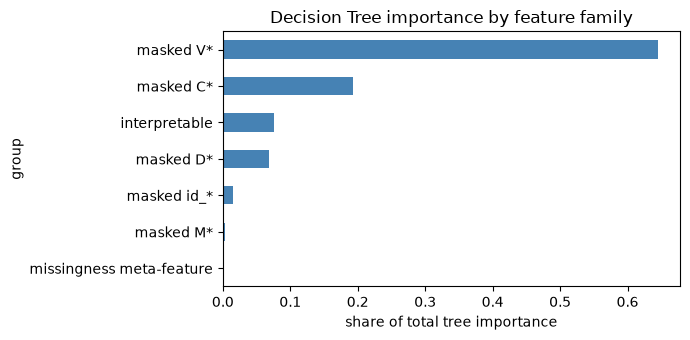

,columns,used,importance_share
group,,,
masked V*,339,22,0.645
masked C*,14,8,0.193
interpretable,30,10,0.076
masked D*,15,6,0.068
masked id_*,39,1,0.015
masked M*,9,2,0.003
missingness meta-feature,5,0,0.000


In [9]:
by_group = (ranking.groupby("group")
            .agg(columns=("column", "size"), used=("importance", lambda s: int((s > 0).sum())),
                 importance_share=("importance", "sum"))
            .sort_values("importance_share", ascending=False))
ax = by_group["importance_share"].plot.barh(color="steelblue", figsize=(7, 3.5))
ax.invert_yaxis(); ax.set_xlabel("share of total tree importance")
ax.set_title("Decision Tree importance by feature family")
plt.tight_layout(); plt.show()
by_group.round(3)

In [10]:
from sklearn.base import clone
from sklearn.linear_model import LogisticRegression

TOP_K = 40
top_columns = set(ranking.head(TOP_K)["column"])
keep = np.array([src in top_columns for src in source_of])
print(f"top {TOP_K} source columns -> {keep.sum()} of {len(keep)} encoded columns")

lr = LogisticRegression(max_iter=1000, class_weight="balanced")
evaluate("Logistic Regression (all encoded columns)", clone(lr))
evaluate(f"Logistic Regression (top-{TOP_K} tree-ranked columns)", clone(lr),
         X_train=X_fit[:, keep], X_eval=X_test[:, keep])

top 40 source columns -> 50 of 626 encoded columns


[Logistic Regression (all encoded columns)] ROC-AUC=0.8356  PR-AUC=0.2129  (30s)


[Logistic Regression (top-40 tree-ranked columns)] ROC-AUC=0.8196  PR-AUC=0.1704  (1s)


,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",'balanced'
,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to

[PCA + Logistic Regression] ROC-AUC=0.8216  PR-AUC=0.1671  (5s)
156 components retain 95% of variance (from 626 encoded columns)


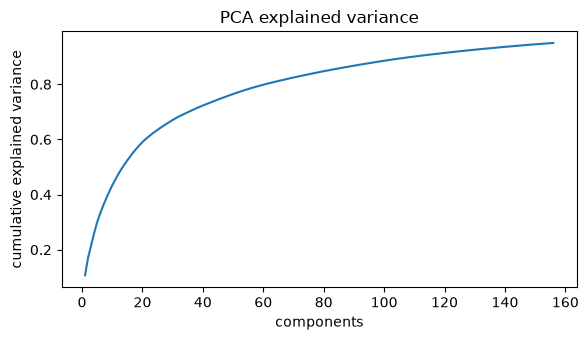

In [11]:
pca_lr = evaluate("PCA + Logistic Regression", models["PCA + Logistic Regression"])
pca = pca_lr.named_steps["pca"]
print(f"{pca.n_components_} components retain 95% of variance (from {pca.n_features_in_} encoded columns)")

fig, ax = plt.subplots(figsize=(6, 3.5))
ax.plot(np.arange(1, pca.n_components_ + 1), np.cumsum(pca.explained_variance_ratio_))
ax.set_xlabel("components"); ax.set_ylabel("cumulative explained variance")
ax.set_title("PCA explained variance")
plt.tight_layout(); plt.show()

## 3. Probabilistic: Gaussian Naive Bayes

**Is it appropriate here?** Only as a fast reference point. Gaussian NB assumes every feature is normally distributed within each class and independent of the others given the class. This data breaks both assumptions:

- **Non-Gaussian:** amounts and counts are heavy-tailed. Median imputation also piles many rows onto a single value.
- **Categorical and sparse:** one-hot columns are 0/1, which a Gaussian models poorly. `BernoulliNB` or `CategoricalNB` suit discrete inputs better.
- **Correlated:** hundreds of related `V` columns count the same evidence many times over. This pushes predicted probabilities towards 0 or 1.

As a result its probabilities are badly calibrated, even when its *ranking* (which is what PR-AUC measures) is usable. The cell below shows how extreme the scores are.

In [12]:
nb = evaluate("Gaussian Naive Bayes", models["Gaussian Naive Bayes"])
p = probas["Gaussian Naive Bayes"]
print(f"share of test scores below 0.01 or above 0.99: {np.mean((p < 0.01) | (p > 0.99)):.1%} "
      f"(XGBoost: {np.mean((xgb_proba < 0.01) | (xgb_proba > 0.99)):.1%})")

[Gaussian Naive Bayes] ROC-AUC=0.7620  PR-AUC=0.0869  (1s)
share of test scores below 0.01 or above 0.99: 98.5% (XGBoost: 1.8%)


## 4. Margin-based: scaled linear SVM

An SVM's margin depends on distances between rows, so a feature with a large range (such as the transaction amount) would dominate unscaled inputs. The shared preprocessing has already **standardised every numeric column on the training sample before fitting**; the check below confirms it. The one-hot columns are already on a 0/1 scale.

`LinearSVC` with **`dual=False`** solves the primal problem. That is the fast choice when rows (~120k) far outnumber columns (~600), and it avoids the slow dual-solver convergence of the earlier version. It uses `max_iter=2000`, `random_state=42`, balanced class weights and the project's `C=0.05`. A kernel SVM doesn't scale to this many rows.

**Calibration without refitting:** the SVM is fit once on the earlier 80% of the training sample. It is then frozen and its margins are sigmoid-calibrated on the chronological validation slice (the latest 20%). This is what `cv="prefit"` used to do. That option was removed in scikit-learn 1.8, and `FrozenEstimator` is its replacement. It replaces the previous 3-fold calibration, which refit the SVM three times.

In [13]:
from sklearn.calibration import CalibratedClassifierCV
from sklearn.frozen import FrozenEstimator
from sklearn.svm import LinearSVC

num_block = X_fit[:, :n_num]
col_means, col_stds = num_block.mean(axis=0), num_block.std(axis=0)
non_constant = col_stds > 1e-6
assert np.allclose(col_means[non_constant], 0, atol=1e-2) and np.allclose(col_stds[non_constant], 1, atol=1e-2), \
    "numeric features are not standardised; refusing to fit the SVM on unscaled inputs"
print(f"scaling check passed: {non_constant.sum()} numeric columns have mean ~0 and std ~1")

start = time.perf_counter()
base_svm = LinearSVC(dual=False, max_iter=2000, random_state=m.RANDOM_STATE,
                     C=0.05, class_weight="balanced").fit(X_early, y_early)
svm = CalibratedClassifierCV(estimator=FrozenEstimator(base_svm), method="sigmoid").fit(X_late, y_late)
record("Linear SVM (calibrated)", svm, svm.predict_proba(X_test)[:, 1],
       time.perf_counter() - start, len(y_early))
print(f"LinearSVC iterations: {base_svm.n_iter_} (cap 2000)")

scaling check passed: 418 numeric columns have mean ~0 and std ~1


[Linear SVM (calibrated)] ROC-AUC=0.8272  PR-AUC=0.2020  (803s)
LinearSVC iterations: 107 (cap 2000)


## 5. Neural network: feed-forward ANN (MLP)

Two hidden layers (128 → 64, ReLU) trained with Adam in mini-batches of 1,024, for **at most 10 epochs**. **Early stopping monitors validation loss** (log-loss on the chronological validation slice) with **patience 3**: training stops after 3 epochs without a new best, and the weights from the best epoch are kept. This mirrors Keras' `EarlyStopping(monitor='val_loss', patience=3, restore_best_weights=True)`. scikit-learn's built-in early stopping watches accuracy, not loss, so the loop is written out explicitly.

Every epoch records training and validation **loss** and **accuracy**. With about 3.5% fraud, a model that never alerts already scores about 96.5% accuracy, so the PR-AUC on the test window is still the number to compare.

early stop at epoch 7: no val_loss improvement for 3 epochs
[Feed-forward ANN (MLP)] ROC-AUC=0.8467  PR-AUC=0.3949  (13s)


best epoch 4 of 7 run (cap 10); best val_loss 0.1077


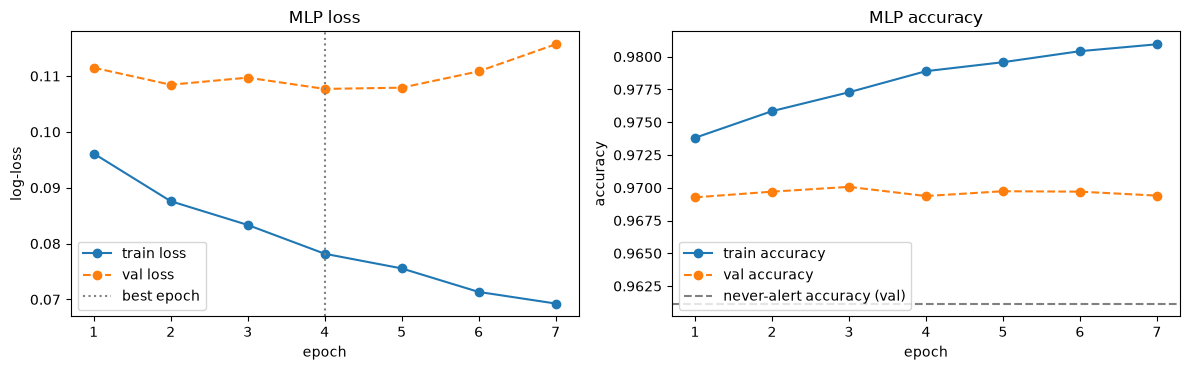

,epoch,train_loss,val_loss,train_accuracy,val_accuracy
0,1,0.0961,0.1115,0.9738,0.9693
1,2,0.0876,0.1084,0.9758,0.9697
2,3,0.0833,0.1097,0.9773,0.9701
3,4,0.0782,0.1077,0.9789,0.9694
4,5,0.0756,0.1079,0.9796,0.9697
5,6,0.0713,0.1108,0.9804,0.9697
6,7,0.0693,0.1157,0.9809,0.9694


In [14]:
import copy
from sklearn.metrics import accuracy_score, log_loss

MAX_EPOCHS, PATIENCE, MIN_DELTA = 10, 3, 1e-4
mlp = clone(models["Feed-forward ANN (MLP)"]).set_params(early_stopping=False)
rng = np.random.default_rng(m.RANDOM_STATE)
history, best_loss, best_mlp, best_epoch, wait = [], np.inf, None, 0, 0

start = time.perf_counter()
for epoch in range(1, MAX_EPOCHS + 1):
    order = rng.permutation(len(y_early))           # reshuffle mini-batches each epoch
    mlp.partial_fit(X_early[order], y_early[order], classes=np.array([0, 1]))
    p_tr, p_va = mlp.predict_proba(X_early)[:, 1], mlp.predict_proba(X_late)[:, 1]
    val_loss = log_loss(y_late, p_va, labels=[0, 1])
    history.append({"epoch": epoch,
                    "train_loss": log_loss(y_early, p_tr, labels=[0, 1]), "val_loss": val_loss,
                    "train_accuracy": accuracy_score(y_early, p_tr >= 0.5),
                    "val_accuracy": accuracy_score(y_late, p_va >= 0.5)})
    if val_loss < best_loss - MIN_DELTA:
        best_loss, best_mlp, best_epoch, wait = val_loss, copy.deepcopy(mlp), epoch, 0
    else:
        wait += 1
        if wait >= PATIENCE:
            print(f"early stop at epoch {epoch}: no val_loss improvement for {PATIENCE} epochs")
            break

mlp = best_mlp  # restore best weights
record("Feed-forward ANN (MLP)", mlp, mlp.predict_proba(X_test)[:, 1],
       time.perf_counter() - start, len(y_early))
curves = pd.DataFrame(history)
print(f"best epoch {best_epoch} of {len(curves)} run (cap {MAX_EPOCHS}); best val_loss {best_loss:.4f}")

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
for col, style in [("train_loss", "-o"), ("val_loss", "--o")]:
    axes[0].plot(curves["epoch"], curves[col], style, label=col.replace("_", " "))
axes[0].axvline(best_epoch, color="gray", linestyle=":", label="best epoch")
axes[0].set_xlabel("epoch"); axes[0].set_ylabel("log-loss"); axes[0].set_title("MLP loss"); axes[0].legend()
for col, style in [("train_accuracy", "-o"), ("val_accuracy", "--o")]:
    axes[1].plot(curves["epoch"], curves[col], style, label=col.replace("_", " "))
axes[1].axhline(1 - y_late.mean(), color="gray", linestyle="--", label="never-alert accuracy (val)")
axes[1].set_xlabel("epoch"); axes[1].set_ylabel("accuracy"); axes[1].set_title("MLP accuracy"); axes[1].legend()
plt.tight_layout(); plt.show()
curves.round(4)

## 6. Leaderboard

In [15]:
full_rows = len(train)
leaderboard = pd.concat([
    pd.DataFrame(results),
    pd.DataFrame([
        {"model": "Logistic Regression (baseline)", **logreg_metrics, "train_rows": full_rows},
        {"model": "XGBoost (champion)", **xgb_metrics, "train_rows": full_rows},
    ]),
], ignore_index=True).sort_values("pr_auc", ascending=False, ignore_index=True)

save_output(leaderboard, "model_comparison.csv")
leaderboard.round(4)

saved <repo>\outputs\model_comparison.csv


,model,roc_auc,pr_auc,train_rows,fit_seconds
0,XGBoost (champion),0.8855,0.4862,472432,NaN
1,Feed-forward ANN (MLP),0.8467,0.3949,120000,12.6
2,Decision Tree,0.8248,0.3369,150000,13.8
3,Logistic Regression (all encoded columns),0.8356,0.2129,150000,30.5
4,Linear SVM (calibrated),0.8272,0.2020,120000,803.5
5,Logistic Regression (top-40 tree-ranked columns),0.8196,0.1704,150000,1.1
6,PCA + Logistic Regression,0.8216,0.1671,150000,4.8
7,Logistic Regression (baseline),0.7577,0.1428,472432,NaN
8,Gaussian Naive Bayes,0.7620,0.0869,150000,0.8


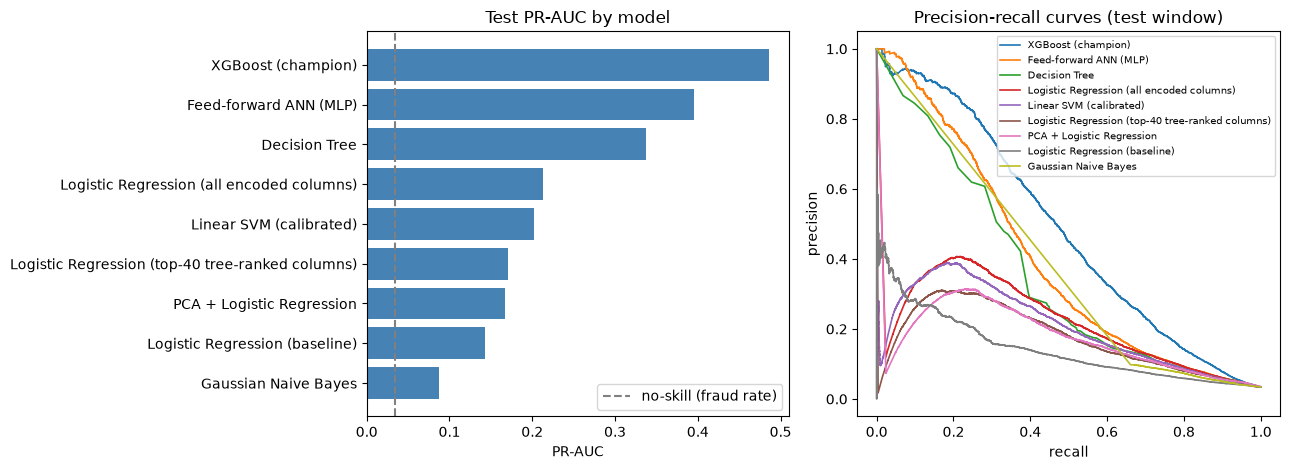

In [16]:
from sklearn.metrics import precision_recall_curve

all_probas = {**probas, "Logistic Regression (baseline)": logreg_proba, "XGBoost (champion)": xgb_proba}

fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
lb = leaderboard.sort_values("pr_auc")
axes[0].barh(lb["model"], lb["pr_auc"], color="steelblue")
axes[0].axvline(y_test.mean(), color="gray", linestyle="--", label="no-skill (fraud rate)")
axes[0].set_xlabel("PR-AUC"); axes[0].set_title("Test PR-AUC by model"); axes[0].legend()

for name in leaderboard["model"]:
    precision, recall, _ = precision_recall_curve(y_test, all_probas[name])
    axes[1].plot(recall, precision, label=name, linewidth=1.2)
axes[1].set_xlabel("recall"); axes[1].set_ylabel("precision")
axes[1].set_title("Precision-recall curves (test window)"); axes[1].legend(fontsize=7)
plt.tight_layout(); plt.show()

## Reading the results

Copy the leaderboard into `REPORT.md` §5 only after a full run on the real data. When interpreting it:

- **Training data:** steps 1–3 saw the `COMPARISON_SAMPLE_SIZE`-row training sample. The SVM and ANN trained on its earlier 80% and used the latest 20% for calibration or early stopping. The baseline and XGBoost saw the full training window. Part of any gap is data volume, not model family.
- **Missing values:** XGBoost handles the block-missing `V` features natively. The other models see median-imputed values, which hides the "this block is empty" signal.
- **Naive Bayes:** judge it on ranking (PR-AUC), not on its probabilities (see §3).
- **Feature selection:** if the top-K Logistic Regression is close to the all-columns one, most of the linear signal sits in a small subset of columns.
- Anything below the dashed no-skill line ranks worse than random.

Next: `05_tuning_and_benchmark.ipynb`.